# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


## Predicción inicial antes de cargar los datos

Antes de observar el dataset Iris, esperaba que la distribución de las medidas tuviera una forma parecida a una campana de Gauss.

También pensé que el dataset tendría más características para describir las flores de una manera más completa. Por ejemplo, esperaba el **color de la flor** y sobre el **tiempo que tarda en crecer**. 

Sin embargo, el dataset Iris solamente incluye cuatro medidas numéricas: longitud y ancho del sépalo, y longitud y ancho del pétalo.


In [11]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

iris = load_iris()
X = iris.data
y = iris.target

print("Cada instancia representa una flor de la especie Iris.")
print(f"Número de instancias: {X.shape[0]}")
print(f"Número de características: {X.shape[1]}")
print(f"Dimensiones de X: {X.shape}")
print(f"Dimensiones de y: {y.shape}")

datos_iris = pd.DataFrame(X, columns=iris.feature_names)

datos_iris["species"] = [iris.target_names[etiqueta] for etiqueta in y]

# Mostrar las primeras 5 instancias
display(datos_iris.head(5))

Cada instancia representa una flor de la especie Iris.
Número de instancias: 150
Número de características: 4
Dimensiones de X: (150, 4)
Dimensiones de y: (150,)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


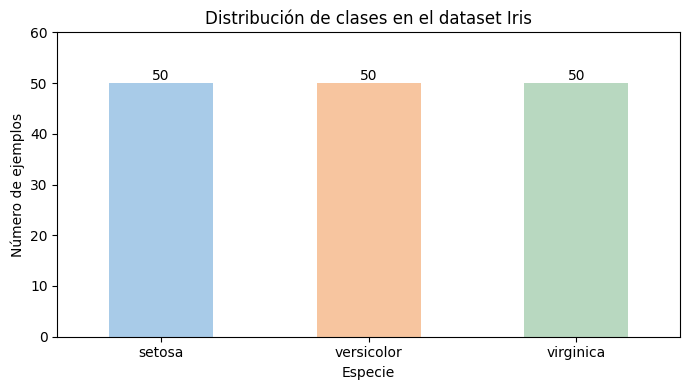

In [12]:
# Gráfico de distribución de las clases
conteo_clases = datos_iris["species"].value_counts().reindex(iris.target_names)

ax = conteo_clases.plot(
    kind="bar",
    color=["#A8CBE8", "#F7C59F", "#B8D8C0"],
    figsize=(7, 4),
    rot=0,
)

ax.set_title("Distribución de clases en el dataset Iris")
ax.set_xlabel("Especie")
ax.set_ylabel("Número de ejemplos")
ax.set_ylim(0, conteo_clases.max() + 10)

# Mostrar la cantidad encima de cada barra
for barra, cantidad in zip(ax.patches, conteo_clases):
    ax.annotate(
        str(cantidad),
        (barra.get_x() + barra.get_width() / 2, barra.get_height()),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

## Interpretación y respuestas

### 1. ¿Qué representa cada instancia?

Cada instancia representa a una Flot y cada fila tiene las cuatro medidas fisicas con su especie dos del sepal y dos del petal

### 2. ¿Cuál es el número de instancias y características?

El dataset contiene 150 instancias y 4 características numéricas por instancia mencionadas en la pregunta anterior. Las instancias son las flores observadas y las características son las medidas utilizadas para describirlas.


### 3. ¿Cuál es el nombre y significado de cada característica?


Las cuatro características están medidas en centímetros y bueno son bastante obvias:

- **Longitud del sépalo** (`sepal length`): 
- **Ancho del sépalo** (`sepal width`): 
- **Longitud del pétalo** (`petal length`):
 - **Ancho del pétalo** (`petal width`): 

Estas características son variables de entrada porque se utilizan para describir cada flor y posteriormente pueden emplearse para predecir su especie. El dataset no incluye características como color o tiempo de crecimiento como yo pensaba



### 4. ¿Cuáles son las clases y cuántos ejemplos hay por clase?

 target usa los códigos 0, 1 y 2 para representar, respectivamente, setosa, versicolor y virginica. Las clases representan las especies de Iris:setosa iris y versicolor cada una con 50 ejemplos y su distribucion es equilibrada Por lo tanto, no hay una clase mayoritaria que pueda dominar el análisis inicial.


### 5. ¿Cuáles son las dimensiones de la matriz de características y del vector de etiquetas?

La matriz de características `X` tiene dimensiones **`(150, 4)`**: sus 150 filas representan las flores y sus 4 columnas representan las medidas de cada flor. y tiene forma (150,): una etiqueta de clase por flor.

# 2. Comparación de clasificadores

## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?
2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?
3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes

Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?